In [2]:
# ==== Cohort Binder (DO NOT MODIFY) ==== 
import hashlib, json, random, numpy as np, datetime, os 
import matplotlib.pyplot as plt 
STUDENT_NAME = input("Enter your full name: ").strip() 
ROLL_NO      = input("Enter your college roll number: ").strip() 
SALT         = "AIML_Capstone_2026"   # fixed by instructor 
sig_str = json.dumps({"n": STUDENT_NAME, "r": ROLL_NO, "s": SALT}) 
STUDENT_SIG = hashlib.sha256(sig_str.encode()).hexdigest()[:12] 
SEED = int(STUDENT_SIG[:8], 16) % (2**31-1) 
random.seed(SEED) 
np.random.seed(SEED) 
TODAY = datetime.date.today().isoformat() 
OUT_PREFIX = f"AIML_{STUDENT_SIG}_{TODAY}" 
os.makedirs("out", exist_ok=True) 
def stamp_plot(title): 
    plt.title(f"{title}\nSIG:{STUDENT_SIG} DATE:{TODAY}") 
print(f"Student: {STUDENT_NAME} | College Roll No: {ROLL_NO}") 
print(f"Signature: {STUDENT_SIG} | Seed: {SEED}") 
print(f"Output prefix: out/{OUT_PREFIX}_*") 

Student: GADAMSETTY NAGA MANIKANTA THARUN | College Roll No: 24UCS123
Signature: c5c95b70276e | Seed: 1170824049
Output prefix: out/AIML_c5c95b70276e_2026-10-02_*


In [3]:
#import necessary libraries 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#import the dataset
housing_data=pd.read_csv('Dataset File/housing.csv')
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
#check if there are any null values 
housing_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [6]:
#there are null values in total_bedrooms column let us get a idea about mean total_bedrooms
housing_data.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
#handle missing values only after train/test split to avoid leakage
from sklearn.model_selection import train_test_split
X=housing_data.drop(columns=["median_house_value"])
y=housing_data["median_house_value"]

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

train_mean=X_train["total_bedrooms"].mean()
X_train["total_bedrooms"]=X_train["total_bedrooms"].fillna(train_mean)
X_test["total_bedrooms"]=X_test["total_bedrooms"].fillna(train_mean)

print("Missing values in train:",X_train["total_bedrooms"].isna().sum())
print("Missing values in test:",X_test["total_bedrooms"].isna().sum())

Missing values in train: 0
Missing values in test: 0


In [8]:
#now the missing values are gone now let us check if there are any duplicate rows
X_train.duplicated().sum()

np.int64(0)

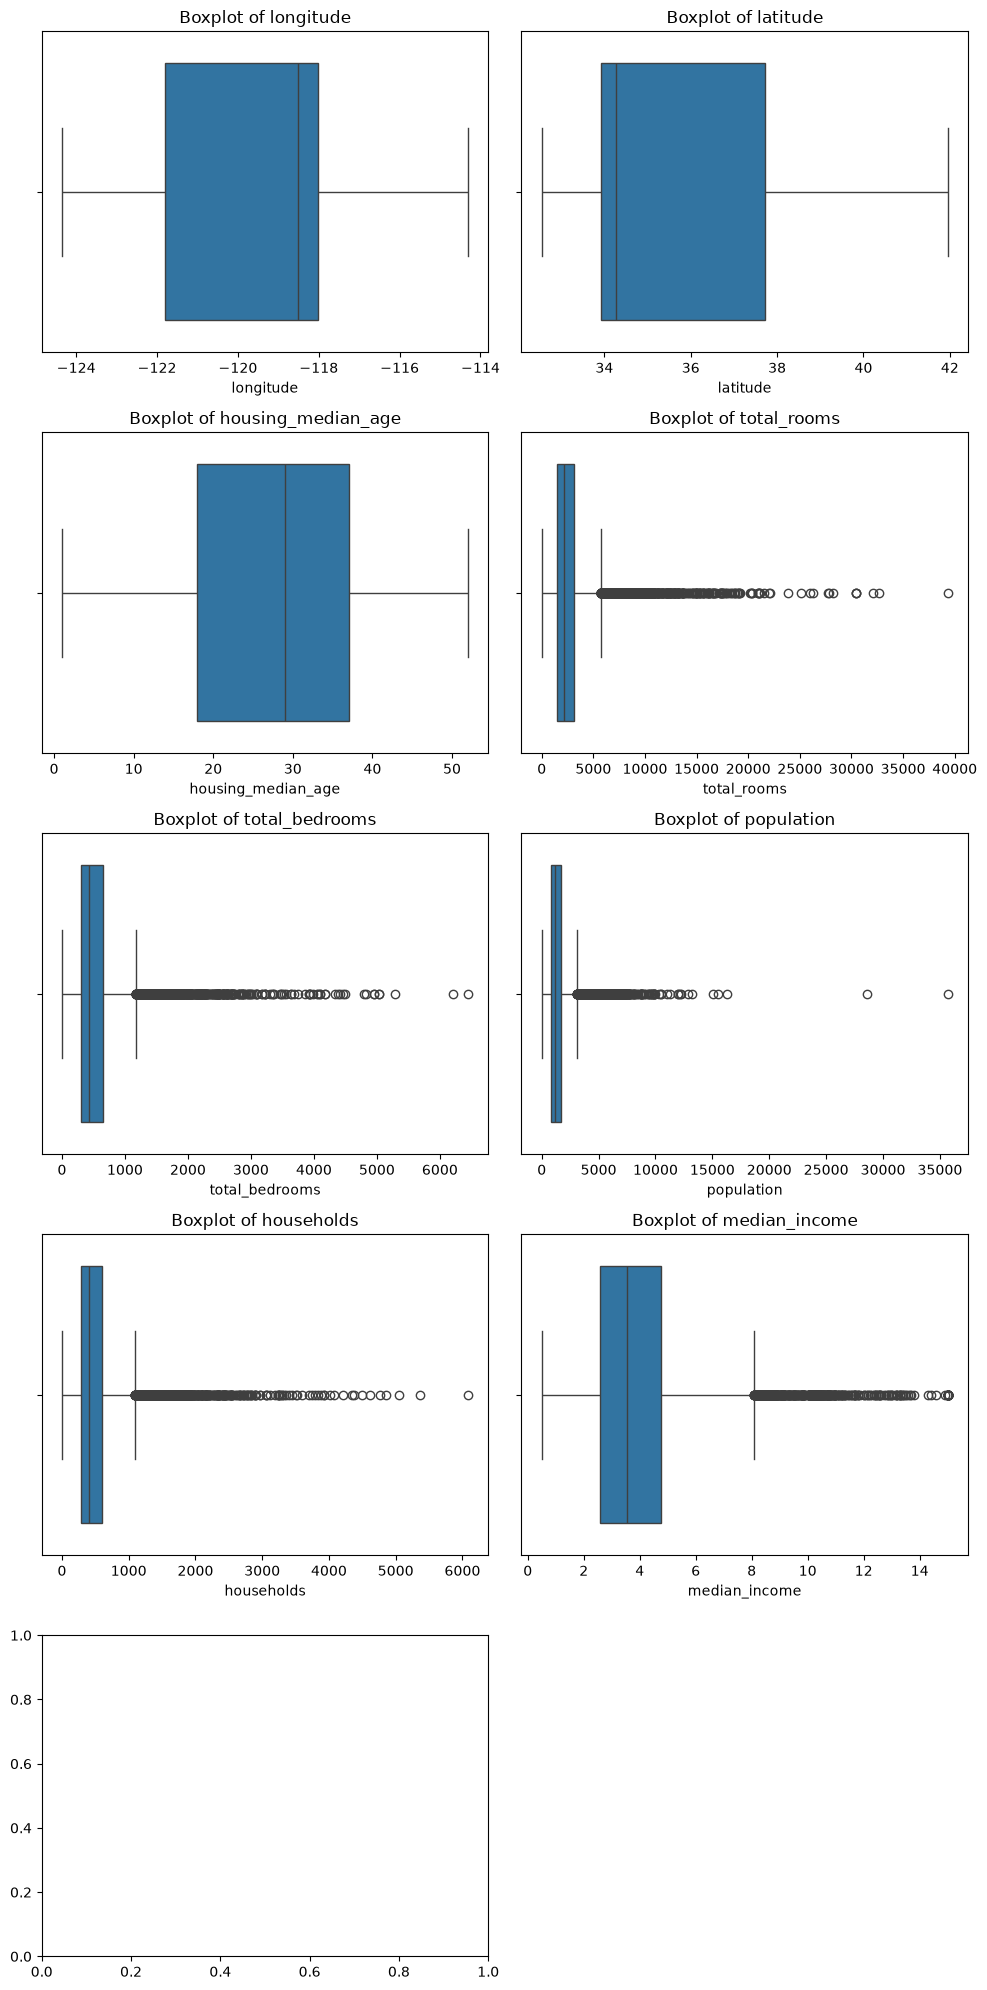

In [9]:
#there are no duplicate rows
#now let us boxplot the numerical columns so that we can get a idea if there are any outliers
numerical_cols=X_train.select_dtypes("float64").columns
fig,axes=plt.subplots(5,2,figsize=(10,20))
axes=axes.flatten()
for i,col in enumerate(numerical_cols):
    sns.boxplot(x=X_train[col],ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel(col)
axes[9].set_visible(False)
plt.tight_layout()
plt.show()

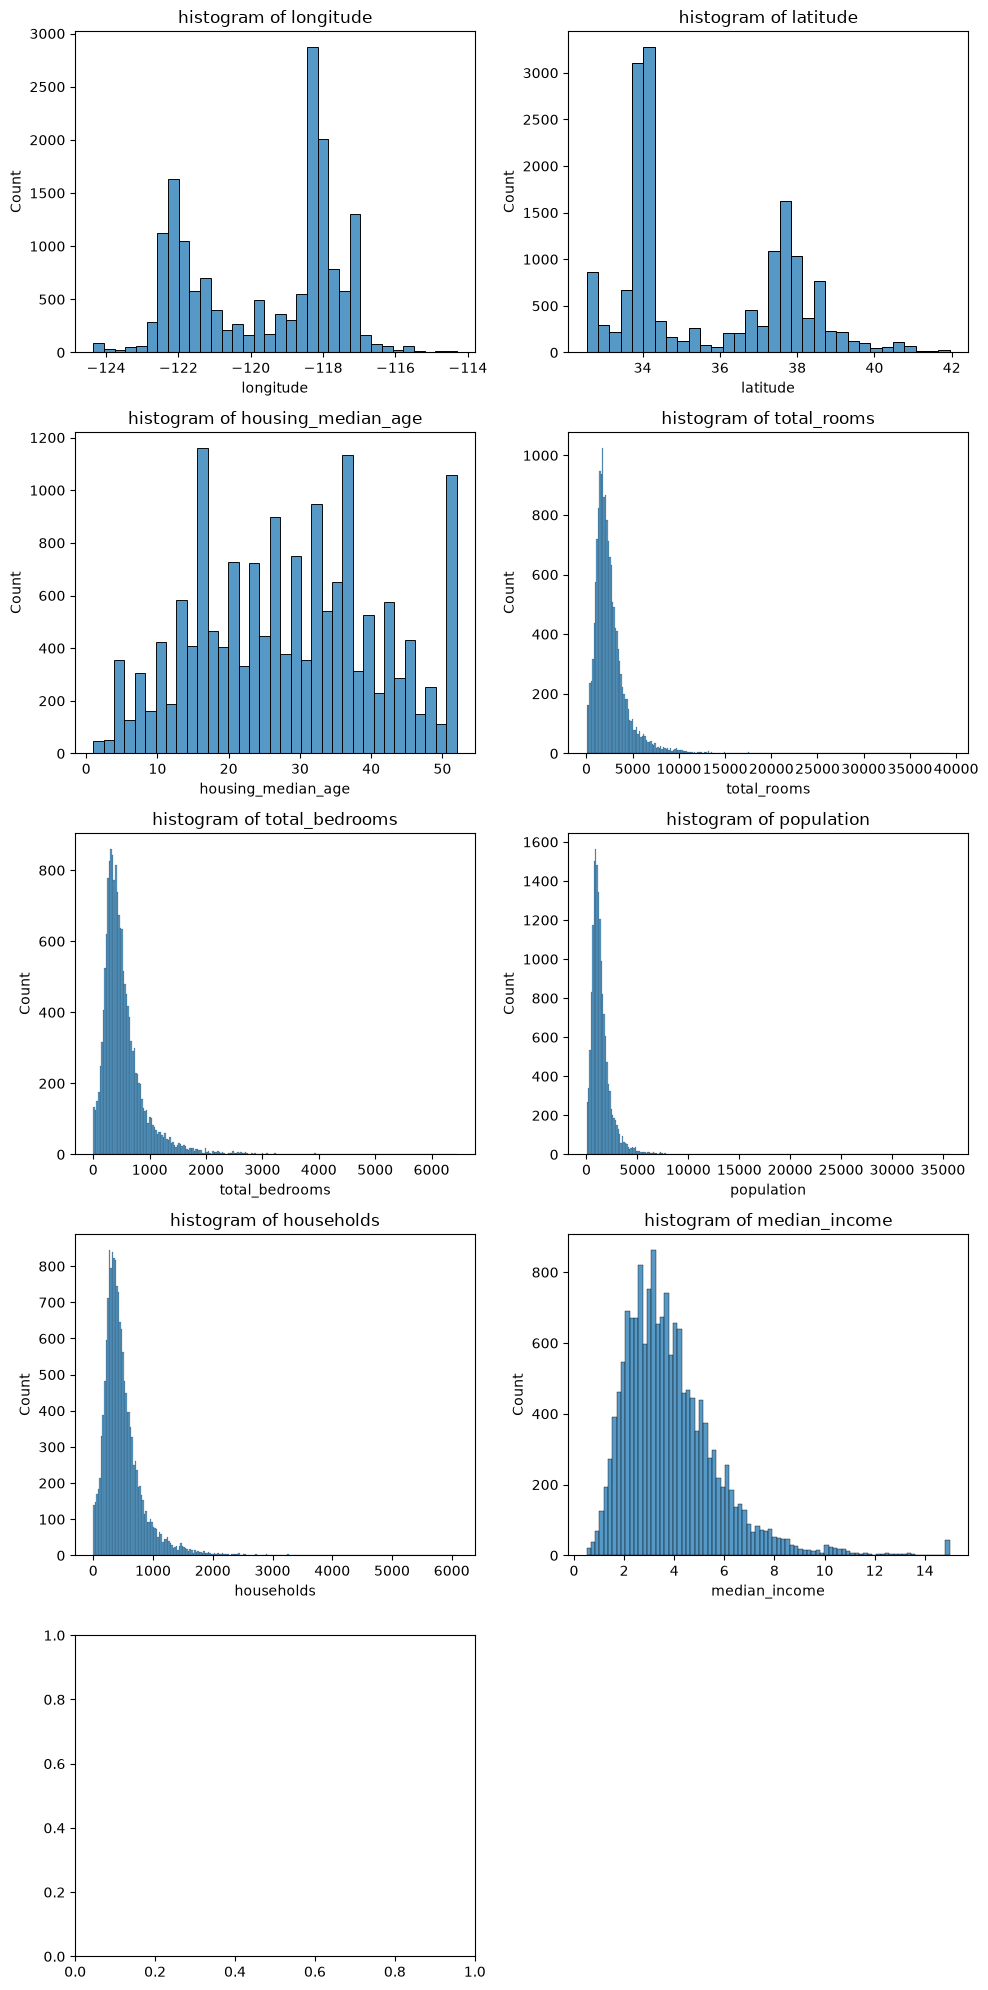

In [10]:
#obviously there are otliers but where there are more population there will be more bedrooms so it will be meaning less to remove them
fig,axes=plt.subplots(5,2,figsize=(10,20))
axes=axes.flatten()
for i,col in enumerate(numerical_cols):
    sns.histplot(x=X_train[col],ax=axes[i])
    axes[i].set_title(f'histogram of {col}')
    axes[i].set_xlabel(col)
axes[9].set_visible(False)
plt.tight_layout()
plt.show()

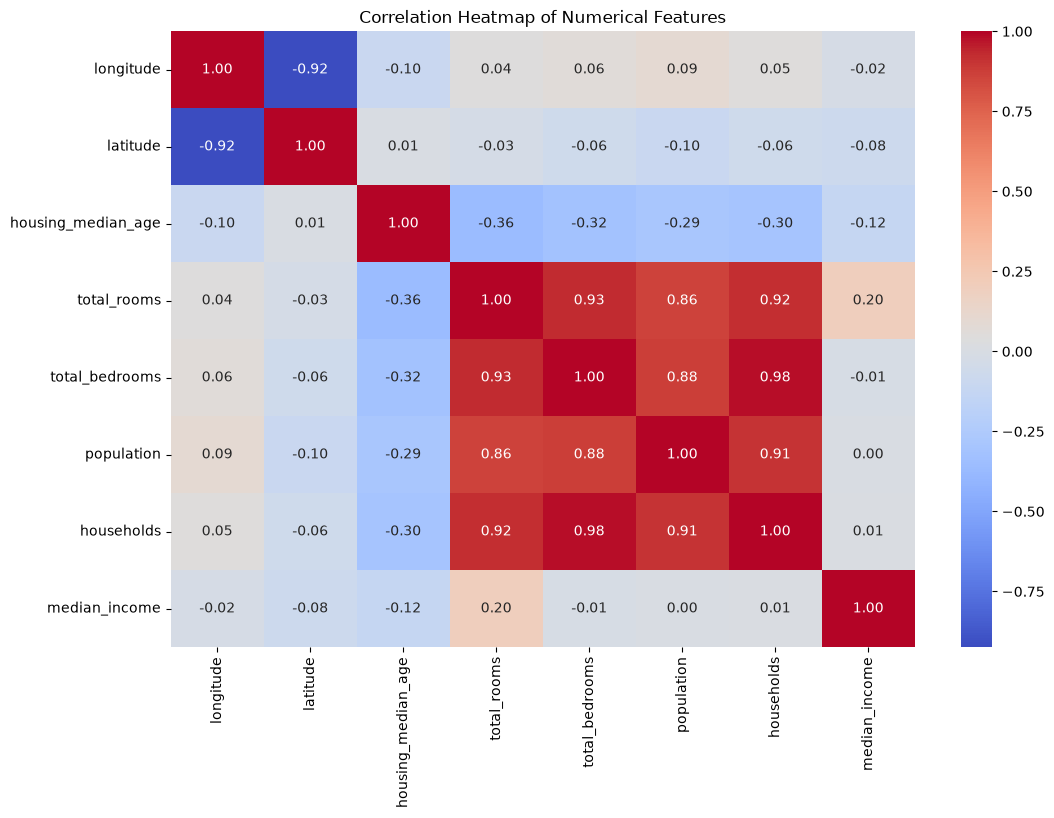

In [11]:
plt.figure(figsize=(12, 8))
numerical_cols=X_train.select_dtypes(include=["float64"])
sns.heatmap(
    numerical_cols.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [12]:
#from above histogram and heatmap we can say that the most of the house values lie between 100000 to 200000 and the next greater house price range 
#is 500000. and as the no of house holds increases the no of total rooms are also increasing showing a positive correlation
X_train["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     7341
INLAND        5227
NEAR OCEAN    2086
NEAR BAY      1854
ISLAND           4
Name: count, dtype: int64

In [13]:
# One-hot encode only after split and align train/test columns
X_train = pd.get_dummies(X_train, columns=["ocean_proximity"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["ocean_proximity"], dtype=int)

# Align columns so train and test match exactly
X_train, X_test = X_train.align(X_test, join="outer", axis=1, fill_value=0)
print(X_train.shape)
print(X_test.shape)

(16512, 13)
(4128, 13)


In [14]:
from sklearn.preprocessing import StandardScaler

# Scale numerical features AFTER split
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

In [15]:
#this is useful in calculating the error and we need to check it always to minimise it
def cost_function(X_train_scaled, y_train, w, b):
    m=len(X_train_scaled)
    cost_sum = 0

    for i in range(m):
        f =np.dot(X_train_scaled[i],w)+b
        cost=(f-y_train[i])**2
        cost_sum+= cost

    total_cost = (1/(2*m))*cost_sum
    return total_cost

In [16]:
#function to calculate the gradients which will be required to get the best w and b values
def gradient_function(X_train_scaled, y_train, w, b):
    m=len(X_train_scaled)
    dc_dw = 0
    dc_db = 0

    for i in range(m):
        f=np.dot(X_train_scaled[i],w)+b

        dc_dw+=(f - y_train[i])*X_train_scaled[i]
        dc_db+=(f-y_train[i])

    dc_dw=(1/m)*dc_dw
    dc_db=(1/m)*dc_db

    return dc_dw,dc_db

In [17]:
# Main body of the linear regression model
def linear_regression(X_train_scaled, y_train, alpha, iterations):
    w = np.zeros(X_train_scaled.shape[1])
    b = 0
    cost_history = []

    for i in range(iterations):
        dc_dw, dc_db = gradient_function(X_train_scaled, y_train, w, b)

        w = w - alpha * dc_dw
        b = b - alpha * dc_db

        cost = cost_function(X_train_scaled, y_train, w, b)
        cost_history.append(cost)

    return w, b, cost_history

In [18]:
learning_rate = 0.01
iterations = 5000

final_w, final_b, cost_history = linear_regression(
    X_train_scaled, y_train, learning_rate, iterations
)

print("Weights:", final_w)
print("Bias:", final_b)
print("Final cost:", cost_history[-1])

Weights: [-40743.30626585 -40779.17960088  14165.63658786 -11045.82026863
  34488.96551892 -43903.5008214   25585.06668366  74981.20823949
   7412.20526581 -15247.79437352   2459.20036738   3506.32636711
   6813.84554056]
Bias: 207194.69373788638
Final cost: 2347081426.346672


In [19]:
#now let us make the prediction function
def predict(X, w, b):
    return np.dot(X, w) + b

In [20]:
y_pred = predict(X_test_scaled, final_w, final_b)

In [21]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})
results.head(10)

,Actual,Predicted
0,47700.0,61671.913240
1,45800.0,128593.275274
2,500001.0,275134.172488
3,218600.0,277378.897230
4,278000.0,267228.117205
5,158700.0,154597.164941
6,198200.0,296294.812288
7,157500.0,234594.482076
8,340000.0,266202.897074
9,446600.0,416946.839601


In [22]:
#let us evaluate the metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("MSE:",mse)
print("RMSE:",rmse)
print("MAE:",mae)
print("R²:",r2)

MSE: 4880415322.242158
RMSE: 69859.96938334683
MAE: 50492.70135368638
R²: 0.6275654850294405


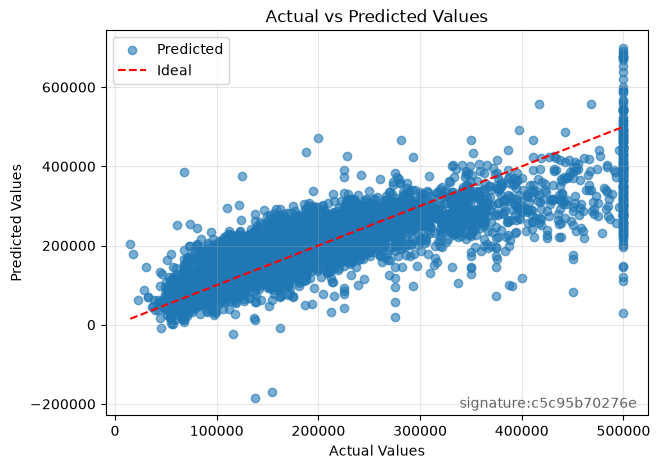

In [23]:
# From above evaluation metrics we can say that
# MSE is mainly used for optimization, not for interpretation, since errors are squared.
# RMSE and MAE together help interpret typical error magnitude.
# If R² is moderate, the model is doing a reasonable job.
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6, label="Predicted")
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    "r--",
    label="Ideal"
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True, alpha=0.3)

# Use the actual generated signature from the cohort binder
plt.text(
    0.98, 0.02, f"signature:{STUDENT_SIG}",
    transform=plt.gca().transAxes,
    ha="right",
    fontsize=10,
    alpha=0.6
)
plt.show()